# Pulsar candidate classification — complete practical
Run the cells top to bottom. Upload `pulsar_data_train.csv` and `pulsar_data_test.csv` to the same folder as this notebook. The supplied test file is **unlabeled**, so final evaluation uses a held-out 20% of the labeled training data.

## Step 1 — Install and import libraries

In [3]:
# Uncomment in a fresh Colab environment if packages are missing:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             fbeta_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, PrecisionRecallDisplay)
import joblib
SEED = 42


## Step 2 — Load and inspect CSV data

In [4]:
train = pd.read_csv('../Data/pulsar_data_train.csv')
test = pd.read_csv('../Data/pulsar_data_test.csv')
train.columns = train.columns.str.strip()
test.columns = test.columns.str.strip()
print('Training:', train.shape, 'Test:', test.shape)
print(train.head())
print(train.info())
print('Missing training values:\n', train.isna().sum())
print('Missing test values:\n', test.isna().sum())
print('Duplicate training rows:', train.duplicated().sum())
print('Class counts:\n', train['target_class'].value_counts(dropna=False))
assert train['target_class'].notna().all(), 'Training labels missing'
assert test['target_class'].isna().all(), 'Test labels were expected to be missing'


Training: (12528, 9) Test: (5370, 9)
   Mean of the integrated profile  \
0                      121.156250   
1                       76.968750   
2                      130.585938   
3                      156.398438   
4                       84.804688   

   Standard deviation of the integrated profile  \
0                                     48.372971   
1                                     36.175557   
2                                     53.229534   
3                                     48.865942   
4                                     36.117659   

   Excess kurtosis of the integrated profile  \
0                                   0.375485   
1                                   0.712898   
2                                   0.133408   
3                                  -0.215989   
4                                   0.825013   

   Skewness of the integrated profile  Mean of the DM-SNR curve  \
0                           -0.013165                  3.168896   
1         

## Step 3 — Exploratory analysis and class imbalance

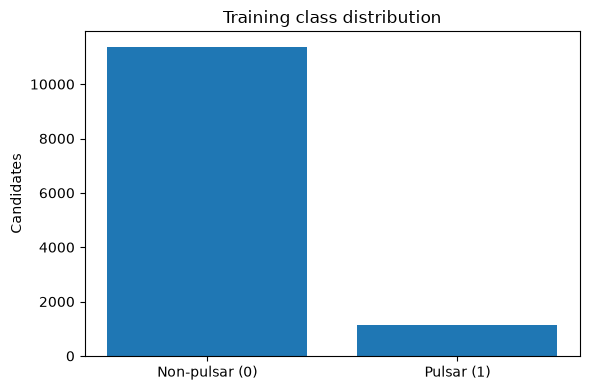

                                                count        mean         std  \
Mean of the integrated profile                12528.0  111.041841   25.672828   
Standard deviation of the integrated profile  12528.0   46.521437    6.801077   
Excess kurtosis of the integrated profile     10793.0    0.478548    1.064708   
Skewness of the integrated profile            12528.0    1.778431    6.208450   
Mean of the DM-SNR curve                      12528.0   12.674758   29.613230   
Standard deviation of the DM-SNR curve        11350.0   26.351318   19.610842   
Excess kurtosis of the DM-SNR curve           12528.0    8.333489    4.535783   
Skewness of the DM-SNR curve                  11903.0  105.525779  107.399585   

                                                    min         25%  \
Mean of the integrated profile                 5.812500  100.871094   
Standard deviation of the integrated profile  24.772042   42.362222   
Excess kurtosis of the integrated profile     -1.738021  

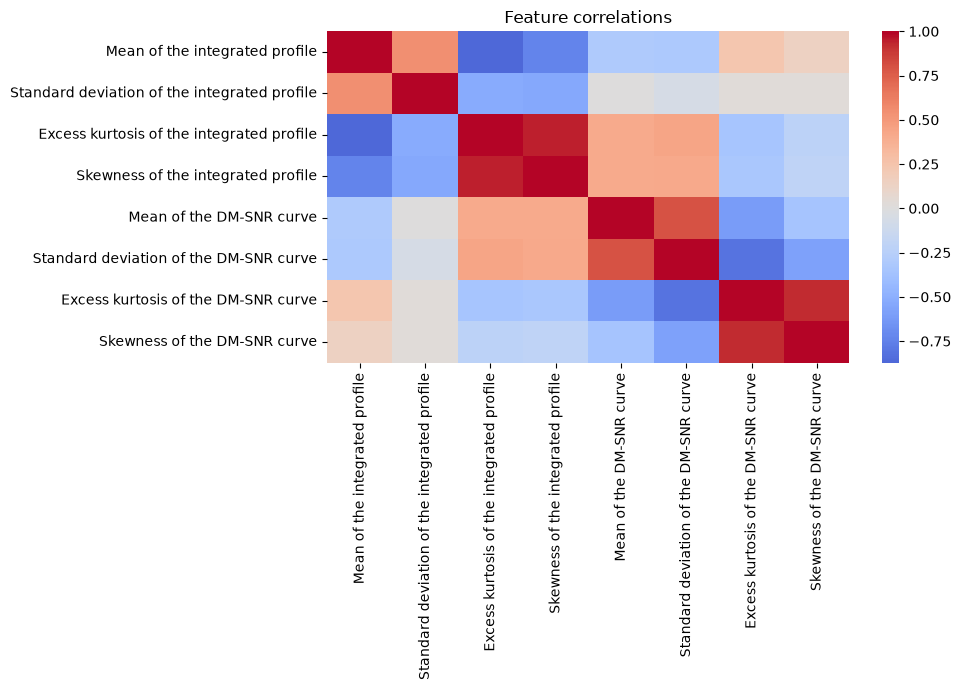

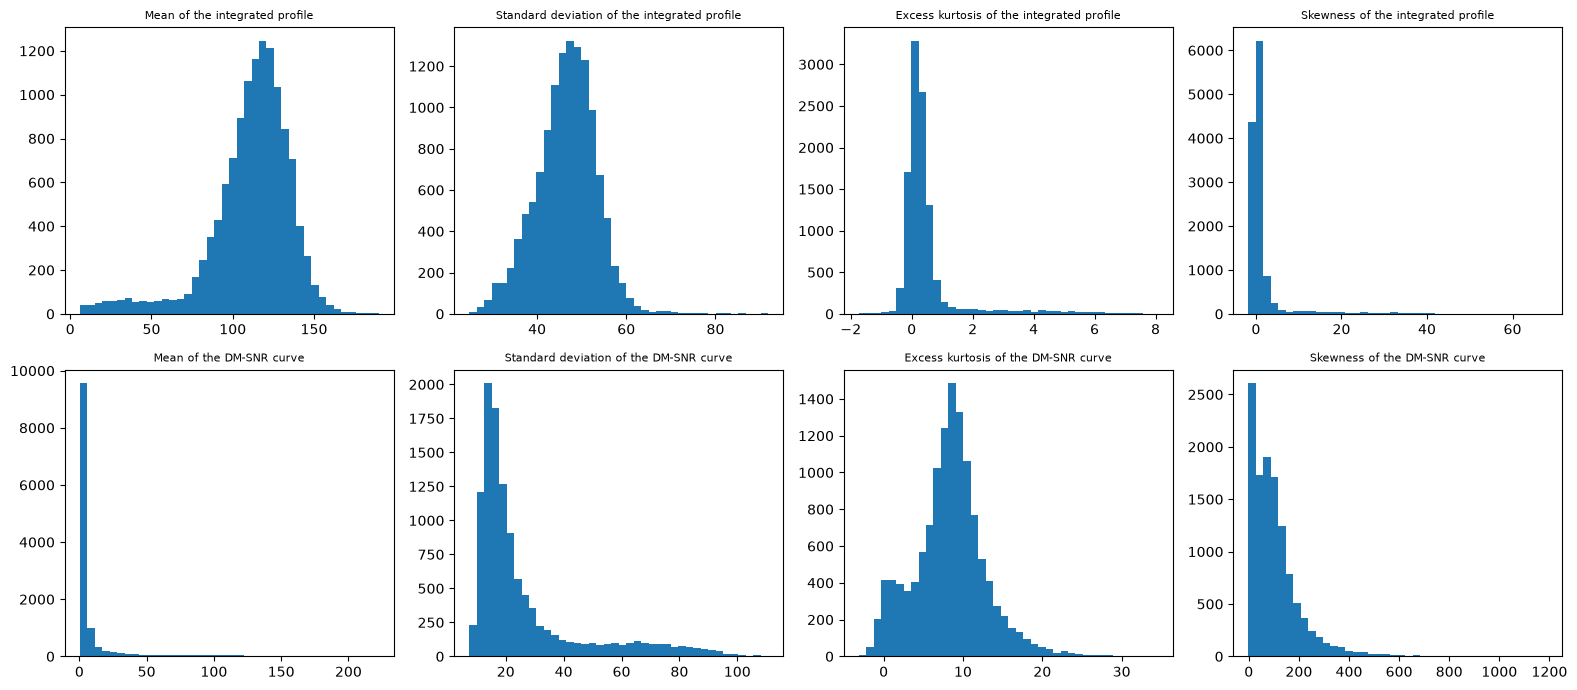

In [5]:
counts = train['target_class'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(6,4))
ax.bar(['Non-pulsar (0)', 'Pulsar (1)'], [counts.get(0, 0), counts.get(1, 0)])
ax.set_title('Training class distribution'); ax.set_ylabel('Candidates')
plt.tight_layout(); plt.show()
feature_cols = [c for c in train.columns if c != 'target_class']
print(train[feature_cols].describe().T)
plt.figure(figsize=(10,7)); sns.heatmap(train[feature_cols].corr(), cmap='coolwarm', center=0); plt.title('Feature correlations'); plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2,4, figsize=(16,7))
for ax, col in zip(axes.ravel(), feature_cols):
    ax.hist(train[col].dropna(), bins=40); ax.set_title(col, fontsize=8)
plt.tight_layout(); plt.show()


## Step 4 — Reserve 20% of labeled rows for final evaluation
Never use these labels during imputer choice, model choice, or feature importance comparisons.

In [6]:
X = train[feature_cols].copy()
y = train['target_class'].astype(int)
X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
print('Development:', X_dev.shape, 'Untouched final holdout:', X_holdout.shape)


Development: (10022, 8) Untouched final holdout: (2506, 8)


## Step 5 — Compare four imputers and two Random Forest class strategies
5-fold CV on development data. Preprocessing is inside each pipeline, avoiding leakage. Iterative RF can be computationally expensive; reduce folds/trees only for a quick exploratory run, then use 5 folds for final reporting.

In [7]:
def make_pipeline(method='median', weighted=False, features=None):
    # Scaling is only used for the distance-based KNN imputer.
    if method == 'mean':
        prep = [('imputer', SimpleImputer(strategy='mean'))]
    elif method == 'median':
        prep = [('imputer', SimpleImputer(strategy='median'))]
    elif method == 'knn':
        prep = [('scaler', StandardScaler()), ('imputer', KNNImputer(n_neighbors=5))]
    elif method == 'iterative_rf':
        prep = [('imputer', IterativeImputer(
            estimator=RandomForestRegressor(n_estimators=20, max_depth=8,
                                            n_jobs=-1, random_state=SEED),
            max_iter=3, random_state=SEED, skip_complete=True
        ))]
    else:
        raise ValueError(method)
    return Pipeline(prep + [('rf', RandomForestClassifier(
        n_estimators=100, random_state=SEED, n_jobs=-1,
        class_weight='balanced' if weighted else None
    ))])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {'accuracy':'accuracy', 'precision':'precision', 'recall':'recall',
           'f1':'f1', 'f2': 'fbeta', 'ap':'average_precision'}
# For F2, scikit-learn needs a custom scorer:
from sklearn.metrics import make_scorer
scoring['f2'] = make_scorer(fbeta_score, beta=2, zero_division=0)
methods = ['mean','median','knn','iterative_rf']
rows = []
for method in methods:
    for weighted in (False, True):
        print('Running:', method, 'weighted:', weighted, flush=True)
        p = make_pipeline(method, weighted)
        scores = cross_validate(p, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=1)
        record = {'imputer':method, 'class_weighted':weighted}
        for metric in scoring:
            record[f'{metric}_mean'] = scores['test_'+metric].mean()
            record[f'{metric}_std'] = scores['test_'+metric].std()
        rows.append(record)
results = pd.DataFrame(rows).sort_values(['f2_mean','ap_mean'], ascending=False)
print(results.to_string(index=False))
results.to_csv('imputation_model_comparison.csv', index=False)


Running: mean weighted: False
Running: mean weighted: True
Running: median weighted: False
Running: median weighted: True
Running: knn weighted: False
Running: knn weighted: True
Running: iterative_rf weighted: False


c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Running: iterative_rf weighted: True


c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\Hasit\Downloads\ML Project\.venv\Lib\site-packages\sklearn\impute\_iterative.py:867: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


     imputer  class_weighted  accuracy_mean  accuracy_std  precision_mean  precision_std  recall_mean  recall_std  f1_mean   f1_std  f2_mean   f2_std  ap_mean   ap_std
         knn            True       0.976451      0.002059        0.877377       0.016673     0.865458    0.023887 0.871061 0.012190 0.867617 0.018435 0.915861 0.011248
iterative_rf            True       0.975254      0.002064        0.869575       0.007625     0.860029    0.024415 0.864589 0.013033 0.861804 0.019742 0.913348 0.013834
      median            True       0.975254      0.001472        0.873199       0.012107     0.855693    0.025873 0.863996 0.010312 0.858913 0.019464 0.910972 0.014393
        mean            True       0.974855      0.001860        0.869627       0.019437     0.855699    0.022939 0.862216 0.010625 0.858205 0.016963 0.913696 0.012972
         knn           False       0.977749      0.001887        0.925066       0.016961     0.825329    0.019348 0.872120 0.011513 0.843382 0.015745 0.913571 0

## Step 6 — Select the best configuration using CV only
Here the primary selection metric is F2, as recall of the rare positive class matters. Record this pre-specified criterion in your report.

In [9]:
best = results.iloc[0]
best_method = str(best['imputer'])
best_weighted = bool(best['class_weighted'])
print('Selected imputer:', best_method)
print('Use class weights:', best_weighted)
print('Mean CV F2:', best['f2_mean'], '+/-', best['f2_std'])


Selected imputer: knn
Use class weights: True
Mean CV F2: 0.8676172210891737 +/- 0.018434865782912226


## Step 7 — Feature-family comparison (on development data only)

In [10]:
groups = {'all_8':feature_cols, 'profile_4':feature_cols[:4], 'dm_snr_4':feature_cols[4:]}
group_rows = []
for group, cols in groups.items():
    p = make_pipeline(best_method, best_weighted)
    s = cross_validate(p, X_dev[cols], y_dev, cv=cv, scoring=scoring, n_jobs=1)
    group_rows.append({'group':group, 'features':len(cols),
                       'f2_mean':s['test_f2'].mean(), 'f2_std':s['test_f2'].std(),
                       'recall_mean':s['test_recall'].mean()})
group_results = pd.DataFrame(group_rows).sort_values('f2_mean', ascending=False)
print(group_results.to_string(index=False))
group_results.to_csv('feature_group_comparison.csv', index=False)


    group  features  f2_mean   f2_std  recall_mean
    all_8         8 0.867617 0.018435     0.865458
profile_4         4 0.858113 0.025775     0.854583
 dm_snr_4         4 0.689240 0.024629     0.701774


## Step 8 — Leave-one-feature-out (LOFO) analysis
A larger drop in cross-validation F2 after dropping a feature suggests larger predictive contribution. Negative drops mean removal improved F2.

                             removed_feature  f2_without  f2_drop
   Excess kurtosis of the integrated profile    0.839568 0.028049
Standard deviation of the integrated profile    0.851646 0.015971
      Standard deviation of the DM-SNR curve    0.862364 0.005253
              Mean of the integrated profile    0.862903 0.004714
         Excess kurtosis of the DM-SNR curve    0.864538 0.003079
          Skewness of the integrated profile    0.865937 0.001680
                    Mean of the DM-SNR curve    0.866159 0.001458
                Skewness of the DM-SNR curve    0.866930 0.000687


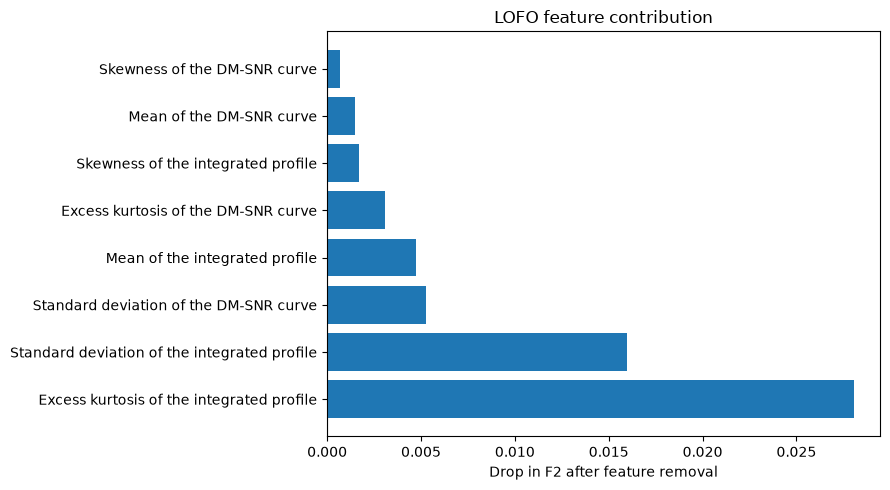

In [11]:
full_scores = cross_validate(make_pipeline(best_method,best_weighted),
                             X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=1)
full_f2 = full_scores['test_f2'].mean()
lofo = []
for drop_col in feature_cols:
    cols = [c for c in feature_cols if c != drop_col]
    s = cross_validate(make_pipeline(best_method,best_weighted),
                       X_dev[cols], y_dev, cv=cv, scoring=scoring, n_jobs=1)
    lofo.append({'removed_feature':drop_col, 'f2_without':s['test_f2'].mean(),
                 'f2_drop':full_f2-s['test_f2'].mean()})
lofo_results = pd.DataFrame(lofo).sort_values('f2_drop', ascending=False)
print(lofo_results.to_string(index=False))
lofo_results.to_csv('leave_one_feature_out.csv', index=False)
plt.figure(figsize=(9,5)); plt.barh(lofo_results['removed_feature'], lofo_results['f2_drop']);
plt.axvline(0, color='gray'); plt.xlabel('Drop in F2 after feature removal');
plt.title('LOFO feature contribution'); plt.tight_layout(); plt.show()


## Step 9 — Fit selected model and evaluate once on untouched holdout

accuracy             0.980048
precision            0.891775
recall               0.891775
f1                   0.891775
f2                   0.891775
average_precision    0.932615
dtype: float64
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      2275
           1       0.89      0.89      0.89       231

    accuracy                           0.98      2506
   macro avg       0.94      0.94      0.94      2506
weighted avg       0.98      0.98      0.98      2506

Confusion matrix [[TN, FP], [FN, TP]]:
 [[2250   25]
 [  25  206]]


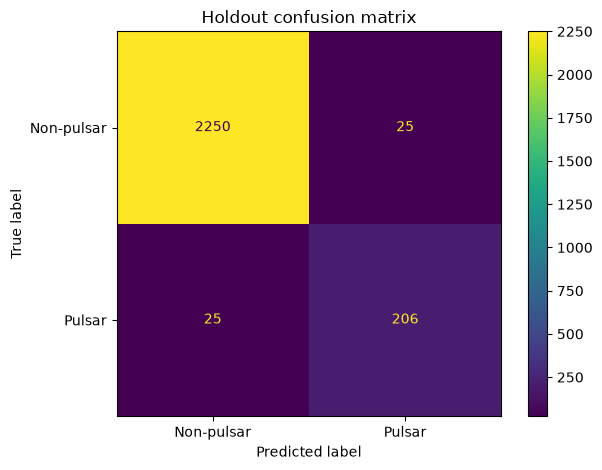

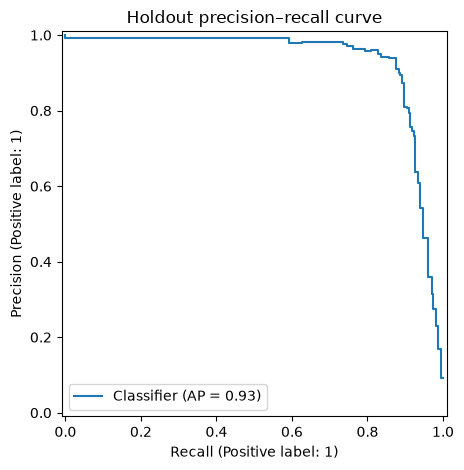

In [14]:
final_validation_model = make_pipeline(best_method, best_weighted)
final_validation_model.fit(X_dev, y_dev)
pred = final_validation_model.predict(X_holdout)
prob = final_validation_model.predict_proba(X_holdout)[:, 1]
metrics = {
    'accuracy':accuracy_score(y_holdout,pred),
    'precision':precision_score(y_holdout,pred,zero_division=0),
    'recall':recall_score(y_holdout,pred,zero_division=0),
    'f1':f1_score(y_holdout,pred,zero_division=0),
    'f2':fbeta_score(y_holdout,pred,beta=2,zero_division=0),
    'average_precision':average_precision_score(y_holdout,prob)
}
print(pd.Series(metrics))
print(classification_report(y_holdout,pred,zero_division=0))
print('Confusion matrix [[TN, FP], [FN, TP]]:\n',confusion_matrix(y_holdout,pred))
ConfusionMatrixDisplay.from_predictions(y_holdout,pred,display_labels=['Non-pulsar','Pulsar'])
plt.title('Holdout confusion matrix'); plt.tight_layout(); plt.show()
PrecisionRecallDisplay.from_predictions(y_holdout,prob)
plt.title('Holdout precision–recall curve'); plt.tight_layout(); plt.show()
pd.Series(metrics, name='score').to_csv('holdout_evaluation.csv')


## Step 10 — Refit on all labeled training data and predict the *unlabeled* supplied test data
Do not report accuracy on the supplied test file because `target_class` is blank there.

In [15]:
assert test[feature_cols].columns.tolist() == feature_cols
final_model = make_pipeline(best_method, best_weighted)
final_model.fit(X, y)
X_test = test[feature_cols].copy()
test_predictions = final_model.predict(X_test).astype(int)
test_probabilities = final_model.predict_proba(X_test)[:,1]
prediction_output = test.copy()
prediction_output['target_class'] = test_predictions
prediction_output['pulsar_probability'] = test_probabilities
prediction_output.to_csv('pulsar_test_predictions.csv', index=False)
joblib.dump(final_model, 'pulsar_random_forest_model.joblib')
print('Saved predictions:',len(prediction_output))
print('Predicted class counts:\n',pd.Series(test_predictions).value_counts())
print(prediction_output[['target_class','pulsar_probability']].head())


Saved predictions: 5370
Predicted class counts:
 0    4904
1     466
Name: count, dtype: int64
   target_class  pulsar_probability
0             0                0.02
1             1                0.76
2             0                0.02
3             1                0.82
4             0                0.03


## Step 11 — Collect the deliverables
Files written by the notebook: `imputation_model_comparison.csv`, `feature_group_comparison.csv`, `leave_one_feature_out.csv`, `holdout_evaluation.csv`, `pulsar_test_predictions.csv`, `pulsar_random_forest_model.joblib`. Include results and graphs in your practical report. **Note:** iterative Random Forest via `IterativeImputer(RandomForestRegressor)` is an approximation to RF iterative imputation, not a claim of reproducing the original missForest package exactly.